# Lab 8
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

## 1. Imports and Setup

### 1.1 Imports and Configuration

In [ ]:
# Import the required libraries
from pathlib import Path
from time import perf_counter
import matplotlib.pyplot as plt
import torch

# Import custom modules
from scripts import lab08_starter as S
from src.gan import (discriminator_loss, generator_loss_original, generator_loss_non_saturating, gradient_penalty, train_digits_gan)
from src.diffusion import (add_noise, noise_prediction_loss, sample_ancestral, sample_deterministic, train_diffusion)

# Print the PyTorch version
print(f'PyTorch version: {torch.__version__}')

PyTorch version: 2.15.0+cpu


In [4]:
# Set the seed for reproducibility
DATA_SEED = 0
EXPERIMENT_SEEDS = (0, 1, 2)
N_SAMPLES = 359

In [5]:
# Display the plots inline
%matplotlib inline

### 1.2 Load and Validate the Digits Dataset

Each 8 × 8 grayscale image is flattened into a vector of 64 pixel values. The dataset contains 1,438 training images and 359 test images. The code below displays the image and label shapes and checks the observed pixel ranges against the expected interval of [0, 1].

In [6]:
# Load the task data
Xtr, ytr, Xte, yte = S.load_task(seed = DATA_SEED)

# Print the shape of the training and test images
print(f'Label shapes: train {tuple(ytr.shape)}, test {tuple(yte.shape)}')
print(f'Training pixel range: [{Xtr.min().item():.2f}, {Xtr.max().item():.2f}]')
print(f'Test pixel range: [{Xte.min().item():.2f}, {Xte.max().item():.2f}]')

Label shapes: train (1438,), test (359,)
Training pixel range: [0.00, 1.00]
Test pixel range: [0.00, 1.00]


## 2. GAN

### 2.1 GAN Losses and Numerical Checks

- The discriminator learns to assign high probabilities to real samples and low probabilities to generated samples. Both generator objectives push the discriminator to classify generated samples as real. The non-saturating objective provides a stronger learning signal when the discriminator confidently identifies generated samples as fake.

- All three losses use softplus to compute their values directly from logits for numerical stability. Each implementation is checked against its probability-based formula using the same randomly generated logits. The absolute difference is reported for each loss.

In [7]:
# Generate random logits
rng = torch.Generator().manual_seed(DATA_SEED)
real_logits = torch.randn(128, generator = rng, dtype = torch.float64)
fake_logits = torch.randn(128, generator = rng, dtype = torch.float64)

# Calculate the probabilities
p_real = real_logits.sigmoid()
p_fake = fake_logits.sigmoid()

# Define the checks
checks = {
    'Discriminator': (discriminator_loss(real_logits, fake_logits), -p_real.log().mean() - torch.log1p(-p_fake).mean()),
    'Generator (original)': (generator_loss_original(fake_logits), torch.log1p(-p_fake).mean()),
    'Generator (non-saturating)': (generator_loss_non_saturating(fake_logits), -p_fake.log().mean())
    }

# Print the results
for name, (actual, expected) in checks.items():
    # Calculate the absolute difference
    error = (actual - expected).abs().item()
    status = 'PASS' if error < 1e-12 else 'FAIL'
    print(f'{name}: {status} | absolute difference = {error:.2e}')

Discriminator: PASS | absolute difference = 2.22e-16
Generator (original): PASS | absolute difference = 1.11e-16
Generator (non-saturating): PASS | absolute difference = 0.00e+00


### 2.2 Optimal Discriminator Check

- The discriminator learns to distinguish real samples from a normal distribution with mean 0 and generated samples from one with mean 1.5. Both distributions have a standard deviation of 1.

- With equal numbers of real and generated samples, the optimal probability that a sample is real is its real-data density divided by the sum of the two densities.

- After 3,000 training steps, the learned probabilities are compared with the theoretical probabilities from -2 to 3.5. The largest absolute difference is reported.

In [8]:
# Initialize the discriminator and optimizer
torch.manual_seed(DATA_SEED)
rng = torch.Generator().manual_seed(DATA_SEED)

# Initialize the discriminator and optimizer
discriminator = S.Discriminator(d_in = 1, d_hidden = 32)
optimizer = torch.optim.Adam(discriminator.parameters(), lr = 3e-3)

# Train on fresh batches from the two fixed distributions
for _ in range(3000):
    real_samples = torch.randn(256, 1, generator = rng)
    fake_samples = torch.randn(256, 1, generator = rng) + 1.5

    optimizer.zero_grad()
    loss = discriminator_loss(discriminator(real_samples), discriminator(fake_samples))
    loss.backward()
    optimizer.step()

# Compare the learned and analytical probabilities
x = torch.linspace(-2.0, 3.5, steps = 551)

# Evaluate the discriminator
discriminator.eval()
with torch.no_grad():
    learned_prob = discriminator(x.unsqueeze(1)).sigmoid()

# Calculate the real and fake densities
real_density = torch.exp(-0.5 * x.square())
fake_density = torch.exp(-0.5 * (x - 1.5).square())
optimal_prob = real_density / (real_density + fake_density)

# Calculate the maximum absolute difference
max_gap = (learned_prob - optimal_prob).abs().max().item()
print(f'Maximum absolute difference: {max_gap:.6f}')

Maximum absolute difference: 0.026696


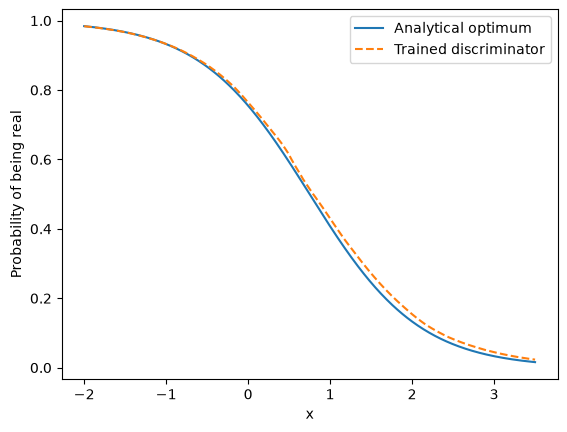

In [9]:
# Plot the results
plt.plot(x, optimal_prob, label = 'Analytical optimum')
plt.plot(x, learned_prob, '--', label = 'Trained discriminator')
plt.xlabel('x')
plt.ylabel('Probability of being real')
plt.legend()

### 2.3 Generator Gradient Saturation

- The generator's output bias is shifted by 6 in both coordinates, placing its samples far from the real ring data. The discriminator is then trained for 300 steps while the generator stays fixed.

- After training, both generator losses are evaluated on the same batch of generated points. The mean probability that these points are real and the mean gradient norm for each loss are reported. The expected result is a weaker gradient from the original loss when the discriminator confidently identifies the generated points as fake.

In [10]:
# Seed model initialization and batch sampling for reproducibility
torch.manual_seed(DATA_SEED)
rng = torch.Generator().manual_seed(DATA_SEED)

# Generate the real ring data and set the batch and noise dimensions
ring, _ = S.ring_of_gaussians(5000, seed = DATA_SEED)
batch_size = 128
noise_dim = 8

# Initialize the generator and discriminator for two-dimensional points
generator = S.Generator(d_noise = noise_dim, d_out = 2)
discriminator = S.Discriminator(d_in = 2)

# Shift the generator's output by 6 along both coordinates
with torch.no_grad():
    generator.net[-1].bias.add_(6.0)

# Configure Adam to update only the discriminator
optimizer = torch.optim.Adam(discriminator.parameters(), lr = 2e-3, betas = (0.5, 0.9))

# Train the discriminator against the fixed generator for 300 steps
for _ in range(300):
    # Sample a batch of real points and draw input noise
    indices = torch.randint(len(ring), (batch_size,), generator = rng)
    real_points = ring[indices]
    noise = torch.randn(batch_size, noise_dim, generator = rng)

    # Generate fake points without tracking gradients through the generator
    with torch.no_grad():
        fake_points = generator(noise)

    # Clear previous gradients and update the discriminator
    optimizer.zero_grad()
    loss = discriminator_loss(discriminator(real_points), discriminator(fake_points))
    loss.backward()
    optimizer.step()

# Draw a fresh batch of generated points for both gradient measurements
noise = torch.randn(batch_size, noise_dim, generator = rng)
with torch.no_grad():
    fake_points = generator(noise)

# Track gradients with respect to the generated coordinates
fake_points.requires_grad_()
fake_logits = discriminator(fake_points)

# Undo the batch mean and keep the graph for the second gradient calculation
original_grad, = torch.autograd.grad(batch_size * generator_loss_original(fake_logits), fake_points, retain_graph = True)

# Apply the same scaling to the non-saturating loss for a fair comparison
non_saturating_grad, = torch.autograd.grad(batch_size * generator_loss_non_saturating(fake_logits), fake_points,)

# Average the discriminator's real probability over the generated batch
mean_real_probability = fake_logits.detach().sigmoid().mean().item()

# Compute the gradient norm for each point, then average across the batch
original_mean_norm = original_grad.norm(dim = 1).mean().item()
non_saturating_mean_norm = non_saturating_grad.norm(dim = 1).mean().item()

# Report discriminator confidence and the gradient signal from each loss
print(f'Mean D(G(z)): {mean_real_probability:.6e}')
print(f'Original loss mean gradient norm: {original_mean_norm:.6e}')
print(f'Non-saturating loss mean gradient norm: {non_saturating_mean_norm:.6e}')

Mean D(G(z)): 1.587712e-09
Original loss mean gradient norm: 9.257525e-09
Non-saturating loss mean gradient norm: 5.844011e+00


The discriminator assigned the generated points a mean real probability of 1.59e-9. The original loss produced a mean gradient norm of 9.26e-9, compared with 5.84 for the non-saturating loss. In this experiment, the original loss provided almost no learning signal once the discriminator confidently identified the generated points as fake.

## 3. Mode Collapse and WGAN-GP

### 3.1 Prediction Before Training

I expect WGAN-GP to achieve higher recall and cover more digit classes than the standard GAN across the three seeds. I expect the standard GAN's predicted digit counts to be more concentrated in a few classes, with some classes rare or absent. The gradient penalty encourages the critic's scores to change smoothly between real and generated samples, which may give the generator a more useful signal for covering a wider variety of digits.

### 3.2 Gradient Penalty Check

WGAN-GP measures the critic's input gradient at randomly selected points between real and generated samples. It computes a gradient norm for each point, squares the difference from 1, and averages the result across the batch.

A linear critic has a constant input gradient, so it gives us two exact checks. A gradient norm of 1 should produce a penalty of 0, and a gradient norm of 3 should produce a penalty of 4.

In [11]:
# Define two pairs of real and generated points for interpolation
real_points = torch.tensor([[0.0, 0.0], [1.0, 0.0]])
fake_points = torch.tensor([[1.0, 1.0], [0.0, 1.0]])
rng = torch.Generator().manual_seed(DATA_SEED)

# Use a linear critic whose input gradient is its weight vector
linear_critic = torch.nn.Linear(2, 1, bias = False)

# Check the penalty for gradient norms of 1 and 3
for expected_norm, expected_penalty in [(1.0, 0.0), (3.0, 4.0)]:
    # Set the weight vector so its norm equals the target
    with torch.no_grad():
        linear_critic.weight.zero_()
        linear_critic.weight[0, 0] = expected_norm

    # Compare the measured penalty with the exact value
    penalty, mean_norm = gradient_penalty(linear_critic, real_points, fake_points, rng = rng)
    measured_penalty = penalty.item()
    status = 'PASS' if abs(measured_penalty - expected_penalty) < 1e-6 else 'FAIL'

    # Report the measured norm and penalty
    print(f'Gradient norm: {mean_norm.item():.1f}')
    print(f'Penalty: {measured_penalty:.1f}')
    print(f'Expected: {expected_penalty:.1f} | {status}')

Gradient norm: 1.0
Penalty: 0.0
Expected: 0.0 | PASS
Gradient norm: 3.0
Penalty: 4.0
Expected: 4.0 | PASS


### 3.3 Train the Standard GAN and WGAN-GP

Both models train on the same digits split for 4,000 generator steps per seed, using batches of 128 images. The standard GAN uses the non-saturating generator loss and one discriminator update per generator update. WGAN-GP uses three critic updates per generator update and a gradient penalty weighted by 10.

For WGAN-GP, the mean critic gradient norm and the gap between real and generated scores are recorded during training. The first 100 and last 500 generator steps are summarized to show how these measurements change.

In [12]:
# Keep the trained generators and run details for Section 3.4
gan_runs = {}

for seed in EXPERIMENT_SEEDS:
    for model_name, use_wgan_gp in [('Standard GAN', False), ('WGAN-GP', True)]:
        # Start both methods from the same initial weights for this seed
        torch.manual_seed(seed)
        generator = S.Generator(d_noise = 16, d_out = 64, d_hidden = 128, out_act = 'sigmoid')
        discriminator = S.Discriminator(d_in = 64, d_hidden = 128)

        # Train one model on the fixed training split
        gradient_history, score_gap_history, training_seconds = train_digits_gan(Xtr, generator, discriminator, seed, use_wgan_gp)

        # Store the generator and runtime for the comparison sections
        gan_runs[(model_name, seed)] = {'generator': generator.eval(), 'training_seconds': training_seconds}
        print(f'{model_name} | seed {seed} | training: {training_seconds:.1f} s')

        if use_wgan_gp:
            # Report the mean gradient norm and score gap for each window
            windows = [('First 100', slice(0, 100)), ('Last 500', slice(-500, None))]
            for label, window in windows:
                norms = gradient_history[window]
                gaps = score_gap_history[window]
                print(f'  {label} steps | gradient norm: {sum(norms) / len(norms):.4f}')
                print(f' | score gap: {sum(gaps) / len(gaps):.4f}')

Standard GAN | seed 0 | training: 28.2 s
WGAN-GP | seed 0 | training: 91.3 s
  First 100 steps | gradient norm: 1.0051
 | score gap: 1.2298
  Last 500 steps | gradient norm: 1.0086
 | score gap: 0.2890
Standard GAN | seed 1 | training: 33.3 s
WGAN-GP | seed 1 | training: 80.8 s
  First 100 steps | gradient norm: 1.0005
 | score gap: 1.1210
  Last 500 steps | gradient norm: 1.0089
 | score gap: 0.2988
Standard GAN | seed 2 | training: 23.5 s
WGAN-GP | seed 2 | training: 78.1 s
  First 100 steps | gradient norm: 1.0029
 | score gap: 1.1585
  Last 500 steps | gradient norm: 1.0086
 | score gap: 0.2955


### 3.4 Compare Sample Quality and Digit Coverage

Each trained generator produces 359 digit images, matching the size of the test set. For each seed, the standard GAN and WGAN-GP receive the same latent inputs. All runs are evaluated with a single feature network trained on the real training images.

Fréchet distance, precision, and recall summarize how the generated samples compare with the test images in feature space. Predicted digit counts show which classes appear and whether the samples are concentrated in a few classes.

In [13]:
# Train one feature network and extract the held-out reference features
feature_net = S.train_feature_net(Xtr, ytr, seed = DATA_SEED).eval()
test_features = S.get_features(feature_net, Xte)

# Create the output folder for the sample grids
output_dir = Path('output')
output_dir.mkdir(exist_ok = True)

for (model_name, seed), run in gan_runs.items():
    # Use the same sampling seed for both methods within each pair
    sample_rng = torch.Generator().manual_seed(10000 + seed)

    # Time the latent draw and generator pass together
    with torch.no_grad():
        start_time = perf_counter()
        noise = torch.randn(N_SAMPLES, 16, generator = sample_rng)
        samples = run['generator'](noise)
        sampling_seconds = perf_counter() - start_time

        # Count classifier predictions in digit order from 0 through 9
        predicted_digits = feature_net(samples).argmax(dim = 1)
        digit_counts = torch.bincount(predicted_digits, minlength = 10)

    # Score the samples and keep the results for the final comparison
    scores = S.score_samples(samples, test_features, feature_net, Xtr)
    digits_present = (digit_counts > 0).sum().item()
    run.update({
        'samples': samples,
        'scores': scores,
        'digit_counts': digit_counts.tolist(),
        'digits_present': digits_present,
        'sampling_seconds': sampling_seconds
        }
    )

    # Print the required metrics for each run
    print(
        f'{model_name} | seed {seed} | Fréchet: {scores["frechet"]:.4f}'
        f' | precision: {scores["precision"]:.4f} | recall: {scores["recall"]:.4f}'
        f' | digits present: {digits_present}/10'
    )
    print(f'Counts for digits 0-9: {run["digit_counts"]}')

    # Save the first 30 samples from the same seed for both models
    if seed == EXPERIMENT_SEEDS[0]:
        filename = 'standard_gan_samples.png' if model_name == 'Standard GAN' else 'wgan_gp_samples.png'
        S.save_grid(samples[:30], output_dir / filename, title = f'{model_name} | seed {seed}')

Standard GAN | seed 0 | Fréchet: 184.5106 | precision: 0.3148 | recall: 0.0000 | digits present: 5/10
Counts for digits 0-9: [56, 0, 0, 24, 112, 50, 0, 0, 117, 0]
WGAN-GP | seed 0 | Fréchet: 4.1609 | precision: 0.8134 | recall: 0.9109 | digits present: 10/10
Counts for digits 0-9: [36, 37, 37, 46, 33, 31, 46, 23, 39, 31]
Standard GAN | seed 1 | Fréchet: 93.6530 | precision: 0.4847 | recall: 0.0028 | digits present: 8/10
Counts for digits 0-9: [70, 55, 33, 52, 79, 56, 2, 0, 12, 0]
WGAN-GP | seed 1 | Fréchet: 4.6852 | precision: 0.7772 | recall: 0.9136 | digits present: 10/10
Counts for digits 0-9: [35, 33, 32, 32, 41, 38, 38, 46, 34, 30]
Standard GAN | seed 2 | Fréchet: 120.6648 | precision: 0.5627 | recall: 0.0000 | digits present: 7/10
Counts for digits 0-9: [114, 0, 62, 29, 0, 22, 26, 0, 33, 73]
WGAN-GP | seed 2 | Fréchet: 4.4279 | precision: 0.7967 | recall: 0.9136 | digits present: 10/10
Counts for digits 0-9: [44, 34, 30, 26, 50, 35, 29, 30, 49, 32]


WGAN-GP achieved higher recall for all three seeds and generated samples classified as all 10 digits in every run. The standard GAN covered 5 to 8 digit classes, with several classes missing and many samples concentrated in a few classes. Its feature-space recall was close to zero, indicating that the generated samples covered very little of the held-out distribution. These results support the prediction in Section 3.1.

## 4. Diffusion

### 4.1 Forward Process and Chain Check

The forward diffusion process adds Gaussian noise in small steps. The same distribution can be sampled directly using the cumulative product of the signal retained at each step.

Starting from 100,000 values equal to 1.5, this check compares the mean and standard deviation from the step-by-step process with those from the direct calculation after 10, 50, and 99 steps.

In [14]:
# Compute per-step and cumulative signal retention from the starter schedule
betas = S.BETAS
alphas = 1 - betas
alpha_bars = alphas.cumprod(dim = 0)

# Start both methods from the same constant signal
rng = torch.Generator().manual_seed(DATA_SEED)
n_values = 100_000
clean = torch.full((n_values,), 1.5)
chain = clean.clone()

# Advance the chain one noise step at a time
for step in range(1, 100):
    # Convert the number of completed steps to a zero-based schedule index
    index = step - 1
    step_noise = torch.randn(n_values, generator = rng)
    chain = alphas[index].sqrt() * chain + betas[index].sqrt() * step_noise

    if step in (10, 50, 99):
        # Draw directly from the same forward distribution
        timesteps = torch.full((n_values,), index, dtype = torch.long)
        direct_noise = torch.randn(n_values, generator = rng)
        direct = add_noise(clean, direct_noise, timesteps, alpha_bars)

        # Compare the mean and standard deviation from both methods
        print(f'After {step} steps')
        print(f'  Chain  | mean: {chain.mean().item():.4f} | std: {chain.std().item():.4f}')
        print(f'  Direct | mean: {direct.mean().item():.4f} | std: {direct.std().item():.4f}')

After 10 steps


  Chain  | mean: 1.4648 | std: 0.2140
  Direct | mean: 1.4662 | std: 0.2130
After 50 steps
  Chain  | mean: 0.7993 | std: 0.8463
  Direct | mean: 0.7998 | std: 0.8476
After 99 steps
  Chain  | mean: 0.1183 | std: 1.0010
  Direct | mean: 0.1152 | std: 0.9931


### 4.2 Noise-Prediction Loss and Ancestral Sampling

During training, each example is assigned a random diffusion step and corrupted with Gaussian noise. The denoiser predicts the added noise, and mean squared error measures the difference between the prediction and the sampled noise.

Ancestral sampling starts from Gaussian noise and runs the learned reverse process one step at a time. Each step uses the predicted noise to calculate the reverse mean. Random noise is added according to the reverse-step variance, with no additional noise on the final step.

In [15]:
# Set up a small batch to check the loss and sampler before training
torch.manual_seed(DATA_SEED)
rng = torch.Generator().manual_seed(DATA_SEED)
demo_denoiser = S.Denoiser(d_data = 2, d_hidden = 128, T = len(betas))
demo_points, _ = S.ring_of_gaussians(16, seed = DATA_SEED)

# Check that the loss can backpropagate through the denoiser
demo_loss = noise_prediction_loss(demo_denoiser, demo_points, alpha_bars, rng = rng)
demo_loss.backward()

# Check that the sampler returns a finite batch of two-dimensional points
initial_noise = torch.randn(16, 2, generator = rng)
demo_samples = sample_ancestral(demo_denoiser.eval(), betas, initial_noise, rng = rng)

# Report the loss, output shape, and whether every sample is finite
print(f'Noise-prediction MSE: {demo_loss.item():.4f}')
print(f'Sample shape: {tuple(demo_samples.shape)}')
print(f'All samples finite: {torch.isfinite(demo_samples).all().item()}')

Noise-prediction MSE: 0.9963
Sample shape: (16, 2)
All samples finite: True


### 4.3 Train and Evaluate on the Ring

The denoiser is trained on a ring of eight Gaussians for 4,000 steps using batches of 128 points. The training data stays fixed across the three seeds.

For each run, ancestral sampling generates 2,000 points. Mode coverage counts how many of the eight clusters are represented, while the share near a mode measures how often generated points land close to a cluster center.

Seed 0 | modes covered: 8/8 | near a mode: 96.3% | training: 15.9 s
Seed 1 | modes covered: 8/8 | near a mode: 96.1% | training: 18.8 s
Seed 2 | modes covered: 8/8 | near a mode: 95.1% | training: 13.8 s


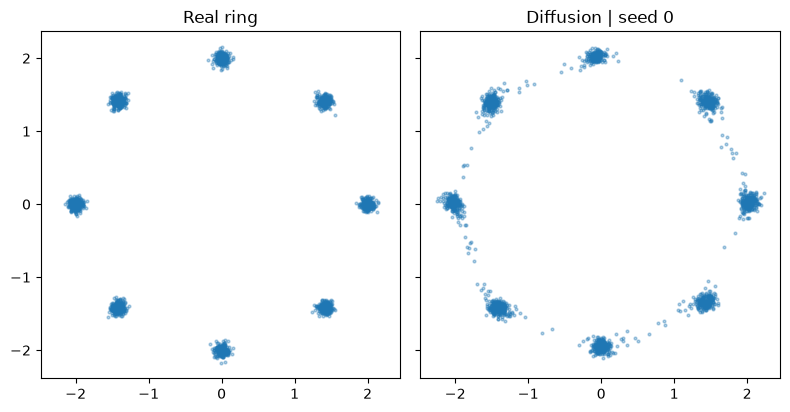

In [ ]:
# Generate a fixed training set for all three runs
ring_train, _ = S.ring_of_gaussians(5000, seed = DATA_SEED)
ring_results = {}

for seed in EXPERIMENT_SEEDS:
    # Initialize and train a two-dimensional denoiser
    torch.manual_seed(seed)
    ring_denoiser = S.Denoiser(d_data = 2, d_hidden = 128, T = len(betas))
    _, training_seconds = train_diffusion(ring_denoiser, ring_train, betas, seed, steps = 4000, batch_size = 128, lr = 2e-3)

    # Generate 2,000 points with the ancestral sampler
    sample_rng = torch.Generator().manual_seed(10000 + seed)
    initial_noise = torch.randn(2000, 2, generator = sample_rng)
    ring_samples = sample_ancestral(
        ring_denoiser.eval(), betas, initial_noise, rng = sample_rng)

    # Measure how many modes appear and how often samples land near them
    modes_covered, share_near_mode = S.mode_coverage(ring_samples)
    ring_results[seed] = {
        'samples': ring_samples,
        'modes_covered': modes_covered,
        'share_near_mode': share_near_mode
        }
    print(
        f'Seed {seed} | modes covered: {modes_covered}/8'
        f' | near a mode: {share_near_mode:.1%}'
        f' | training: {training_seconds:.1f} s'
        )

# Compare real and generated points at the same scale using the first seed
plot_seed = EXPERIMENT_SEEDS[0]
fig, axes = plt.subplots(1, 2, figsize = (8, 4), sharex = True, sharey = True)

# Plot 2,000 points in each panel
for ax, points, title in [(axes[0], ring_train[:2000], 'Real ring'), (axes[1], ring_results[plot_seed]['samples'], f'Diffusion | seed {plot_seed}')]:
    ax.scatter(points[:, 0], points[:, 1], s = 4, alpha = 0.35)
    ax.set_title(title)
    ax.set_aspect('equal', adjustable = 'box')

# Save the figure for the README and display it in the notebook
fig.tight_layout()
fig.savefig(output_dir / 'diffusion_ring.png', dpi = 150, bbox_inches = 'tight')
plt.show()

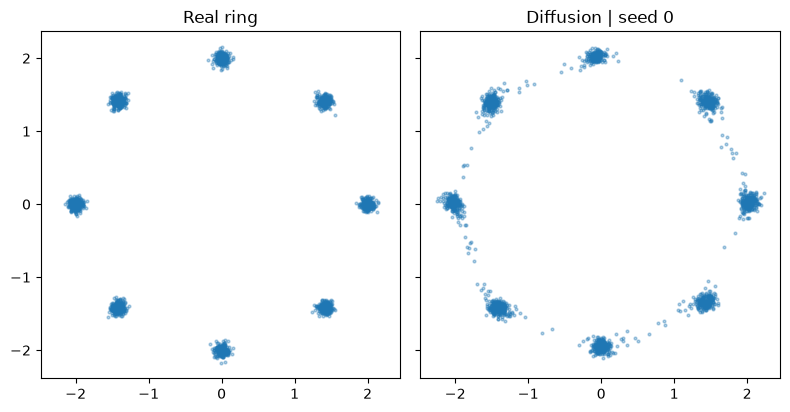

In [18]:
# Compare real and generated points at the same scale using the first seed
plot_seed = EXPERIMENT_SEEDS[0]
fig, axes = plt.subplots(1, 2, figsize = (8, 4), sharex = True, sharey = True)

# Plot 2,000 points in each panel
for ax, points, title in [(axes[0], ring_train[:2000], 'Real ring'),(axes[1], ring_results[plot_seed]['samples'], f'Diffusion | seed {plot_seed}'),]:
    ax.scatter(points[:, 0], points[:, 1], s = 4, alpha = 0.35)
    ax.set_title(title)
    ax.set_aspect('equal', adjustable = 'box')

# Save the figure for the README and display it in the notebook
fig.tight_layout()
fig.savefig(output_dir / 'diffusion_ring.png', dpi = 150, bbox_inches = 'tight')
plt.show()

### 4.4 Train and Evaluate on Digits

The training images are rescaled from [0, 1] to [-1, 1]. A denoiser with hidden width 256 is trained for 4,000 steps per seed with batches of 128 images. The learning rate starts at 0.001 and decays to zero using a cosine schedule.

For each seed, ancestral sampling generates 359 images. The samples are mapped back to [0, 1], clipped, and scored using the same feature network and test features as the GANs. The mean noise-prediction loss is reported for the first 100 and last 200 training steps.

In [29]:
# Rescale the training images for diffusion
diffusion_train = 2 * Xtr - 1

# Report how much of the original signal amplitude remains at the final step
signal_amplitude = alpha_bars[-1].sqrt().item()
print(f'Original signal amplitude at the final step: {signal_amplitude:.2%}')

# Keep trained models, samples, and metrics for Sections 5 and 6
diffusion_runs = {}

for seed in EXPERIMENT_SEEDS:
    # Initialize and train one digits denoiser
    torch.manual_seed(seed)
    denoiser = S.Denoiser(d_data = 64, d_hidden = 256, T = len(betas))
    loss_history, training_seconds = train_diffusion(denoiser, diffusion_train, betas, seed, steps = 4000, batch_size = 128, lr = 1e-3, use_cosine = True)
    denoiser.eval()

    # Time the initial noise draw and the full ancestral sampling run
    sample_rng = torch.Generator().manual_seed(10000 + seed)
    start_time = perf_counter()
    initial_noise = torch.randn(N_SAMPLES, 64, generator = sample_rng)
    raw_samples = sample_ancestral(denoiser, betas, initial_noise, rng = sample_rng)
    sampling_seconds = perf_counter() - start_time

    # Convert samples to the pixel range used by the shared evaluation
    samples = ((raw_samples + 1) / 2).clamp(0, 1)
    scores = S.score_samples(samples, test_features, feature_net, Xtr)

    # Summarize early and late training losses
    early_loss = sum(loss_history[:100]) / 100
    late_loss = sum(loss_history[-200:]) / 200

    # Store the initial noise so Section 5 can reuse it across samplers
    diffusion_runs[seed] = {
        'denoiser': denoiser,
        'initial_noise': initial_noise,
        'samples': samples,
        'scores': scores,
        'training_seconds': training_seconds,
        'sampling_seconds': sampling_seconds,
    }

    # Report the loss windows and generated sample metrics for this seed
    print(f'Seed {seed} | training: {training_seconds:.1f} s')
    print(f'  First 100 steps MSE: {early_loss:.4f} | Last 200 steps MSE: {late_loss:.4f}')
    print(
        f'  Fréchet: {scores["frechet"]:.4f} | precision: {scores["precision"]:.4f}'
        f' | recall: {scores["recall"]:.4f}'
    )

# Save a sample grid using the same seed as the GAN grids
grid_seed = EXPERIMENT_SEEDS[0]
S.save_grid(diffusion_runs[grid_seed]['samples'][:30], output_dir / 'diffusion_digit_samples.png', title = f'Diffusion digits | seed {grid_seed}')

Original signal amplitude at the final step: 7.50%
Seed 0 | training: 26.0 s
  First 100 steps MSE: 0.6248 | Last 200 steps MSE: 0.1843
  Fréchet: 11.2151 | precision: 0.8162 | recall: 0.8524
Seed 1 | training: 23.0 s
  First 100 steps MSE: 0.6332 | Last 200 steps MSE: 0.1853
  Fréchet: 13.5635 | precision: 0.7688 | recall: 0.8162
Seed 2 | training: 21.7 s
  First 100 steps MSE: 0.6313 | Last 200 steps MSE: 0.1845
  Fréchet: 13.3217 | precision: 0.7939 | recall: 0.8273


## 5. Sampling Steps and Sampler Choice

### 5.1 Deterministic Sampler

The deterministic sampler selects evenly spaced steps from the training noise schedule. At each selected step, the denoiser predicts the noise and uses it to estimate the clean image. The sampler then moves directly to the next selected step without drawing new noise.

### 5.2 Compare Step Counts

For each of the three trained denoisers, the deterministic sampler is evaluated with 5, 10, 25, 50, and 100 model evaluations. All configurations start from the same 359 noise vectors used by the ancestral sampler for that seed. Each set of images is scored with the same feature network and test features.

In [27]:
# Set the deterministic evaluation counts and store the scores by seed
step_counts = (5, 10, 25, 50, 100)
sampler_results = {}

for seed in EXPERIMENT_SEEDS:
    # Reuse the trained model, initial noise, and ancestral baseline
    run = diffusion_runs[seed]
    denoiser = run['denoiser']
    initial_noise = run['initial_noise']
    sampler_results[seed] = {('Ancestral', len(betas)): run['scores']}

    for steps in step_counts:
        # Sample from the same initial noise using the selected step budget
        raw_samples = sample_deterministic(denoiser, betas, initial_noise, steps = steps)

        # Map the samples back to the feature network's pixel range
        samples = ((raw_samples + 1) / 2).clamp(0, 1)
        scores = S.score_samples(samples, test_features, feature_net, Xtr)
        sampler_results[seed][('Deterministic', steps)] = scores

    # Report the ancestral baseline and every deterministic configuration
    print(f'\nSeed {seed}')
    for (sampler, steps), scores in sampler_results[seed].items():
        print(
            f'  {sampler:<13} | steps: {steps:>3} | Fréchet: {scores["frechet"]:.4f}'
            f' | precision: {scores["precision"]:.4f} | recall: {scores["recall"]:.4f}'
        )


Seed 0
  Ancestral     | steps: 100 | Fréchet: 11.2151 | precision: 0.8162 | recall: 0.8524
  Deterministic | steps:   5 | Fréchet: 7.0152 | precision: 0.7827 | recall: 0.9081
  Deterministic | steps:  10 | Fréchet: 7.0755 | precision: 0.7716 | recall: 0.8969
  Deterministic | steps:  25 | Fréchet: 7.8903 | precision: 0.7688 | recall: 0.8997
  Deterministic | steps:  50 | Fréchet: 8.1112 | precision: 0.7660 | recall: 0.8969
  Deterministic | steps: 100 | Fréchet: 8.2320 | precision: 0.7577 | recall: 0.8942

Seed 1
  Ancestral     | steps: 100 | Fréchet: 13.5635 | precision: 0.7688 | recall: 0.8162
  Deterministic | steps:   5 | Fréchet: 15.8202 | precision: 0.7214 | recall: 0.9164
  Deterministic | steps:  10 | Fréchet: 13.1537 | precision: 0.7242 | recall: 0.9192
  Deterministic | steps:  25 | Fréchet: 12.8540 | precision: 0.7270 | recall: 0.9415
  Deterministic | steps:  50 | Fréchet: 12.9181 | precision: 0.7270 | recall: 0.9387
  Deterministic | steps: 100 | Fréchet: 12.9639 | prec

### 5.3 Separate Step-Count and Sampler Effects

The 100-step deterministic sampler is the reference for both comparisons. Comparing it with the 100-step ancestral sampler measures the effect of changing the sampler at a fixed step count. Comparing each shorter deterministic run with the 100-step deterministic run measures the effect of reducing the step count while keeping the sampler fixed.

The two changes add up to the total recall difference between each shorter deterministic run and the 100-step ancestral baseline. Positive values indicate higher recall.

In [26]:
# Print a compact table with recall changes in percentage points
print('Seed | Steps | Sampler change | Step-count change | Total change')

for seed, results in sampler_results.items():
    # Compare samplers at the same 100-step budget
    ancestral_recall = results[('Ancestral', 100)]['recall']
    deterministic_recall = results[('Deterministic', 100)]['recall']
    sampler_change = deterministic_recall - ancestral_recall

    for steps in (5, 10, 25, 50):
        # Compare step counts within the deterministic sampler
        short_recall = results[('Deterministic', steps)]['recall']
        step_change = short_recall - deterministic_recall

        # Report both changes and the total relative to ancestral sampling
        total_change = short_recall - ancestral_recall
        print(
            f'{seed:>4} | {steps:>5} | {100 * sampler_change:>+14.2f}'
            f' | {100 * step_change:>+17.2f} | {100 * total_change:>+12.2f}'
        )

Seed | Steps | Sampler change | Step-count change | Total change
   0 |     5 |          +4.18 |             +1.39 |        +5.57
   0 |    10 |          +4.18 |             +0.28 |        +4.46
   0 |    25 |          +4.18 |             +0.56 |        +4.74
   0 |    50 |          +4.18 |             +0.28 |        +4.46
   1 |     5 |         +12.26 |             -2.23 |       +10.03
   1 |    10 |         +12.26 |             -1.95 |       +10.31
   1 |    25 |         +12.26 |             +0.28 |       +12.53
   1 |    50 |         +12.26 |             +0.00 |       +12.26
   2 |     5 |          +5.57 |             +2.79 |        +8.36
   2 |    10 |          +5.57 |             +0.84 |        +6.41
   2 |    25 |          +5.57 |             -0.84 |        +4.74
   2 |    50 |          +5.57 |             -0.84 |        +4.74


## 6. Compare the Three Model Families

### 6.1 Train the VAE Baseline

The starter VAE is trained on the same digits training split using its default settings of 200 epochs, a batch size of 64, and a learning rate of 0.002. One model is trained per seed.

Each model generates 359 images by drawing latent vectors from a standard normal distribution and decoding them in one pass. The samples are scored using the same feature network and held-out test features as WGAN-GP and diffusion.

In [30]:
# Store one VAE sample set and its results per seed
vae_runs = {}

for seed in EXPERIMENT_SEEDS:
    # Seed the model initialization and train using the starter defaults
    torch.manual_seed(seed)
    vae = S.VAE()
    start_time = perf_counter()
    S.train_vae(vae, Xtr, seed = seed)
    training_seconds = perf_counter() - start_time
    vae.eval()

    # Time the latent draw and the single decoder pass
    start_time = perf_counter()
    samples = vae.sample(N_SAMPLES, seed = 10000 + seed)
    sampling_seconds = perf_counter() - start_time

    # Score the generated images and store the inputs for Section 6.2
    scores = S.score_samples(samples, test_features, feature_net, Xtr)
    vae_runs[seed] = {'samples': samples, 'scores': scores, 'training_seconds': training_seconds, 'sampling_seconds': sampling_seconds}

    # Report quality metrics and runtime for this seed
    print(f'Seed {seed} | training: {training_seconds:.1f} s | sampling: {sampling_seconds:.4f} s')
    print(
        f'  Fréchet: {scores["frechet"]:.4f} | precision: {scores["precision"]:.4f}'
        f' | recall: {scores["recall"]:.4f}'
    )

# Save a sample grid using the same seed as the GAN and diffusion grids
grid_seed = EXPERIMENT_SEEDS[0]
S.save_grid(vae_runs[grid_seed]['samples'][:30], output_dir / 'vae_digit_samples.png', title = f'VAE digits | seed {grid_seed}')

Seed 0 | training: 14.9 s | sampling: 0.0016 s
  Fréchet: 13.9586 | precision: 0.9136 | recall: 0.4930
Seed 1 | training: 14.0 s | sampling: 0.0006 s
  Fréchet: 13.5713 | precision: 0.8802 | recall: 0.4345
Seed 2 | training: 18.7 s | sampling: 0.0006 s
  Fréchet: 15.6522 | precision: 0.8858 | recall: 0.4652


### 6.2 Compare Quality, Coverage, and Runtime

WGAN-GP, diffusion with 100-step ancestral sampling, and the VAE are compared across three seeds. Each run uses 359 generated images and is evaluated with the same feature network and test set.

For each generated image, the pixel-space distance to the closest training image is measured. The mean summarizes the typical distance, and the minimum identifies the closest match among all generated images. Total variation distance compares the predicted digit proportions with the true test-set digit proportions.

Training time and sampling time are reported separately. A network evaluation means one forward pass over the full batch of 359 images.

In [25]:
# Compute the reference digit proportions from the true test labels
test_digit_counts = torch.bincount(yte, minlength = 10)
test_digit_proportions = test_digit_counts / test_digit_counts.sum()

# Collect the three model families and their network evaluation counts
family_results = {}

for seed in EXPERIMENT_SEEDS:
    runs = [('WGAN-GP', gan_runs[('WGAN-GP', seed)], 1), ('Diffusion', diffusion_runs[seed], len(betas)), ('VAE', vae_runs[seed], 1)]

    for model_name, run, evaluations in runs:
        samples = run['samples']

        # Measure the distance from each sample to its closest training image
        nearest_distances = S.nearest_train_distance(samples, Xtr)

        # Estimate the generated digit proportions with the shared classifier
        with torch.no_grad():
            predicted_digits = feature_net(samples).argmax(dim = 1)
        generated_counts = torch.bincount(predicted_digits, minlength = 10)
        generated_proportions = generated_counts / generated_counts.sum()

        # Compute half the sum of absolute differences between digit proportions
        digit_tv = 0.5 * (generated_proportions - test_digit_proportions).abs().sum().item()

        # Store the required metrics for this model and seed
        family_results[(model_name, seed)] = {
            'frechet': run['scores']['frechet'],
            'precision': run['scores']['precision'],
            'recall': run['scores']['recall'],
            'mean_nearest': nearest_distances.mean().item(),
            'min_nearest': nearest_distances.min().item(),
            'digit_tv': digit_tv,
            'training_seconds': run['training_seconds'],
            'sampling_seconds': run['sampling_seconds'],
            'evaluations': evaluations
            }

# Report sample quality and digit coverage for every run
print('Model     | Seed | Fréchet | Precision | Recall | Digit TV')
for (model_name, seed), scores in family_results.items():
    print(
        f'{model_name:<9} | {seed:>4} | {scores["frechet"]:>7.4f}'
        f' | {scores["precision"]:>9.4f} | {scores["recall"]:>6.4f}'
        f' | {scores["digit_tv"]:>8.4f}'
    )

# Report nearest-training distances and runtime for every run
print('\nModel     | Seed | Mean NN | Min NN | Train (s) | Draw (s) | Evals')
for (model_name, seed), scores in family_results.items():
    print(
        f'{model_name:<9} | {seed:>4} | {scores["mean_nearest"]:>7.4f}'
        f' | {scores["min_nearest"]:>6.4f} | {scores["training_seconds"]:>9.2f}'
        f' | {scores["sampling_seconds"]:>8.4f} | {scores["evaluations"]:>5}'
    )

Model     | Seed | Fréchet | Precision | Recall | Digit TV
WGAN-GP   |    0 |  4.1609 |    0.8134 | 0.9109 |   0.0975
Diffusion |    0 | 11.2151 |    0.8162 | 0.8524 |   0.1031
VAE       |    0 | 13.9586 |    0.9136 | 0.4930 |   0.1226
WGAN-GP   |    1 |  4.6852 |    0.7772 | 0.9136 |   0.0808
Diffusion |    1 | 13.5635 |    0.7688 | 0.8162 |   0.0947
VAE       |    1 | 13.5713 |    0.8802 | 0.4345 |   0.1393
WGAN-GP   |    2 |  4.4279 |    0.7967 | 0.9136 |   0.1337
Diffusion |    2 | 13.3217 |    0.7939 | 0.8273 |   0.1504
VAE       |    2 | 15.6522 |    0.8858 | 0.4652 |   0.1476

Model     | Seed | Mean NN | Min NN | Train (s) | Draw (s) | Evals
WGAN-GP   |    0 |  1.3073 | 0.5980 |     91.29 |   0.0015 |     1
Diffusion |    0 |  1.4573 | 0.9545 |     22.19 |   0.2491 |   100
VAE       |    0 |  1.1387 | 0.5648 |     13.63 |   0.0054 |     1
WGAN-GP   |    1 |  1.3186 | 0.5866 |     80.75 |   0.0029 |     1
Diffusion |    1 |  1.4800 | 0.9490 |     21.63 |   0.1767 |   100
VAE    

### 6.3 Conclusion and Limitations

**WGAN-GP** was the best choice for generating diverse digits quickly after training. It had the lowest Fréchet distance (4.16-4.69), the highest recall (0.9109-0.9136), and the smallest digit-distribution gap for every seed. It generated 359 images in one network evaluation, but took the longest to train at 78.11–91.29 seconds per run.

**Diffusion** was the best choice when the sampling budget needed to be adjustable. It trained in 21.11–22.19 seconds, and the deterministic sampler could generate images in as few as five evaluations. At a fixed budget of 100 evaluations, switching from ancestral to deterministic sampling improved recall by 4.18–12.26 percentage points across the three seeds. The 100-step ancestral sampler took 0.1767-0.2491 seconds per batch and had a higher Fréchet distance than WGAN-GP in every run.

**The VAE** was the best choice for a baseline that could be retrained quickly. It trained in 13.63-15.41 seconds, generated the full batch in one evaluation, and had the highest precision (0.8802-0.9136). Its recall was the lowest (0.4345-0.4930), and its samples were closest to training images on average in pixel space. That makes it a weaker choice when broad coverage is important.

These comparisons use one digits dataset and split, one feature network, three seeds, and 359 generated images per run. Digit coverage depends on the classifier's predictions, and runtimes reflect the local setup and the training budgets used in this lab.